In [1]:
import warnings
import hoomd

import numpy as np
import unyt as u
import math
import itertools

import flowermd.utils

warnings.filterwarnings("ignore")

In [4]:
from flowermd.base import BaseHOOMDForcefield

class DPD(BaseHOOMDForcefield):
    """A DPD forcefield to use with bead-spring systems.

    Notes
    -----
    This is designed to be used with `flowermd.library.polymers.LJChain`

    The set of interactions are:
    1. `hoomd.md.pair.DPD`
    2. `hoomd.md.bond.Harmonic`
    3. `hoomd.md.angle.Harmonic` (optional)

    Parameters
    ----------
    A : int, required
        DPD pair-wise drag force coefficient
    gamma : int, required
        DPD pair-wise random force coefficient
    kT : float, required
        Temperature used in pair-wise drag force
    r_cut : float, required
        Cut off radius for pair interactions
    bond_k : float, default 100
        Spring constant in harmonic bond.
    bond_r0: float, deault 1.0
        Equilibrium distance between 2 ellipsoid tips.
    angle_k : float, optional
        Spring constant in harmonic angle.
    angle_theta0: float, optional
        Equilibrium angle between 2 consecutive beads.
    nlist : type, default hoomd.md.nlist.Cell
        A class (not an instance) of the HOOMD neighbor list
        to use for the pair force.
    nlist_buffer : float, default 0.40
        The buffer value (distance) used by the neighbor list.

    """

    def __init__(
        self,
        A,
        gamma,
        kT,
        r_cut,
        bead_name="_A",
        bond_k=100,
        bond_r0=1.0,
        angle_k=None,
        angle_theta0=None,
        nlist=hoomd.md.nlist.Cell,
        nlist_buffer=0.40,
    ):
        self.A = A
        self.gamma = gamma
        self.kT = kT
        self.r_cut = r_cut
        self.bead_name = bead_name
        self.angle_k = angle_k
        self.angle_theta0 = angle_theta0
        self.bond_k = bond_k
        self.bond_r0 = bond_r0
        self.pair = (self.bead_name, self.bead_name)
        self.bond_type = f"{self.bead_name}-{self.bead_name}"
        self.angle_type = f"{self.bead_name}-{self.bead_name}-{self.bead_name}"
        self.nlist = nlist
        self.nlist_buffer = nlist_buffer
        hoomd_forces = self._create_forcefield()
        super(DPD, self).__init__(hoomd_forces)

    def _create_forcefield(self):
        forces = []
        # Bonds
        bond = hoomd.md.bond.Harmonic()
        bond.params[self.bond_type] = dict(k=self.bond_k, r0=self.bond_r0)
        # Angles
        if all([self.angle_k, self.angle_theta0]):
            angle = hoomd.md.angle.Harmonic()
            angle.params[self.angle_type] = dict(
                k=self.angle_k, t0=self.angle_theta0
            )
        # DPD Pairs
        nlist = self.nlist(buffer=self.nlist_buffer, exclusions=["bond"])
        dpd = hoomd.md.pair.DPD(
            nlist=nlist, kT=self.kT, default_r_cut=self.r_cut
        )
        dpd.params[self.pair] = dict(A=self.A, gamma=self.gamma)
        forces.append(dpd)
        forces.append(bond)
        if all([self.angle_k, self.angle_theta0]):
            forces.append(angle)

        return forces

In [12]:
from flowermd.library import PhantomWalk
from flowermd.library import RandomWalk
from flowermd.base import Molecule

In [18]:
density = np.linspace(0.5, 1.5, 100)
particle_separation=[]

print(density)

for d in density:
    print(d)
    ring_mol = Molecule(num_mols=100, smiles="s1ssss1",)
    
    system = RandomWalk(
        molecules=ring_mol,
        density=d * u.Unit("nm**-3"), #number density - spheres per unit volume, changes based on system!!!
        bond_length=1.0,
    )
    
    dpd = DPD(
        A=250000,
        gamma=1500,
        kT=1.0,
        r_cut=1.01,
        bead_name="S",
        bond_k=250000,
    )
    
    sim = PhantomWalk.from_system(
        system=system,
        forcefield=dpd.hoomd_forces,
        n_steps_dpd=500,
        n_steps_fire=100,
        gsd_write_freq=100,
        log_write_freq=100,
    )
    particle_separation.append(sim.particle_separation)

print(density)
print(particle_separation)

[0.5        0.51010101 0.52020202 0.53030303 0.54040404 0.55050505
 0.56060606 0.57070707 0.58080808 0.59090909 0.6010101  0.61111111
 0.62121212 0.63131313 0.64141414 0.65151515 0.66161616 0.67171717
 0.68181818 0.69191919 0.7020202  0.71212121 0.72222222 0.73232323
 0.74242424 0.75252525 0.76262626 0.77272727 0.78282828 0.79292929
 0.8030303  0.81313131 0.82323232 0.83333333 0.84343434 0.85353535
 0.86363636 0.87373737 0.88383838 0.89393939 0.9040404  0.91414141
 0.92424242 0.93434343 0.94444444 0.95454545 0.96464646 0.97474747
 0.98484848 0.99494949 1.00505051 1.01515152 1.02525253 1.03535354
 1.04545455 1.05555556 1.06565657 1.07575758 1.08585859 1.0959596
 1.10606061 1.11616162 1.12626263 1.13636364 1.14646465 1.15656566
 1.16666667 1.17676768 1.18686869 1.1969697  1.20707071 1.21717172
 1.22727273 1.23737374 1.24747475 1.25757576 1.26767677 1.27777778
 1.28787879 1.2979798  1.30808081 1.31818182 1.32828283 1.33838384
 1.34848485 1.35858586 1.36868687 1.37878788 1.38888889 1.39898

Text(0, 0.5, 'particle separation')

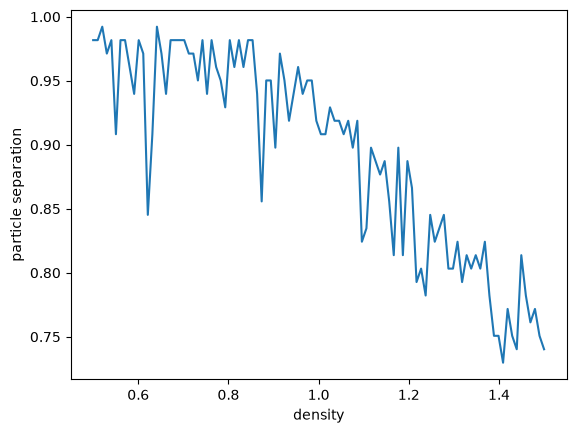

In [27]:
import matplotlib.pyplot as plt

plt.plot(density, particle_separation)
plt.xlabel("density")
plt.ylabel("particle separation")

In [20]:
for writer in sim.operations.writers:
    if isinstance(writer, hoomd.write.GSD):
        writer.flush()

sim.particle_separation

np.float64(0.7402499914169312)

In [26]:
ring_mol = Molecule(num_mols=100, smiles="s1ssss1",)

ring_mol.molecules[0].visualize()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

sim.run_NVT(n_steps=1000, kT=1, tau_kt=0.01)

for writer in sim.operations.writers:
    if isinstance(writer, hoomd.write.GSD):
        writer.flush()

In [21]:
from cmeutils.visualize import FresnelGSD

sim_visualizer = FresnelGSD(
    gsd_file="trajectory.gsd", frame=0, view_axis=(1, 1, 1)
)

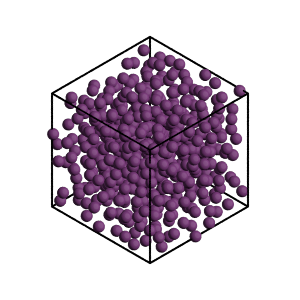

In [22]:
sim_visualizer.frame = -1
sim_visualizer.view()

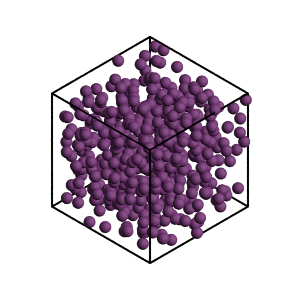

In [23]:
sim_visualizer.frame = 0
sim_visualizer.view()